# Hybrid Search RAG — Chapter 6
## BM25 Implementation in Practice
### Notebook-First RMM Edition

This notebook moves from **understanding BM25 mathematically** to **building, using, debugging, updating, benchmarking, and integrating a practical BM25 retriever**.

## Learning Flow

```text
BM25 recap
   ↓
Corpus preparation
   ↓
Reusable retriever class
   ↓
Query scoring
   ↓
Top-K search
   ↓
Score explanation
   ↓
Batch search
   ↓
Add / update / delete documents
   ↓
Rebuild index safely
   ↓
rank_bm25 library
   ↓
Benchmarking
   ↓
Filtering + tests + debugging
   ↓
Production architecture
```

## You will learn

- Index-time vs query-time work
- Reusable tokenizer and corpus preparation
- BM25 retriever class design
- Metadata preservation
- Top-K retrieval
- Term-level score explanation
- Corpus updates and reindexing
- `rank_bm25` usage
- Latency measurement
- Regression tests
- Filtering
- Production BM25 architecture
- How BM25 becomes the lexical branch of Hybrid Search

# 0. Main Mental Model

```text
INDEX TIME
Documents
   ↓
Tokenize
   ↓
TF / DF / lengths / avgdl
   ↓
BM25 index state

QUERY TIME
User query
   ↓
Tokenize
   ↓
BM25 score
   ↓
Sort
   ↓
Top-K
```

The key engineering principle is: **do expensive corpus work once, not on every query**.

# 1. Setup

Examples use only simple topics such as cats, dogs, apples, books and travel.

In [1]:
import math
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Setup complete.")

Setup complete.


# 2. BM25 Recap

A common BM25 term contribution is:

$$
IDF(q) \times \frac{TF(q,D)(k_1+1)}{TF(q,D)+k_1(1-b+b|D|/avgdl)}
$$

Where:

```text
IDF   → rarity
TF    → frequency in this document
k1    → TF saturation control
b     → document-length normalization
|D|   → current document length
avgdl → average document length
```

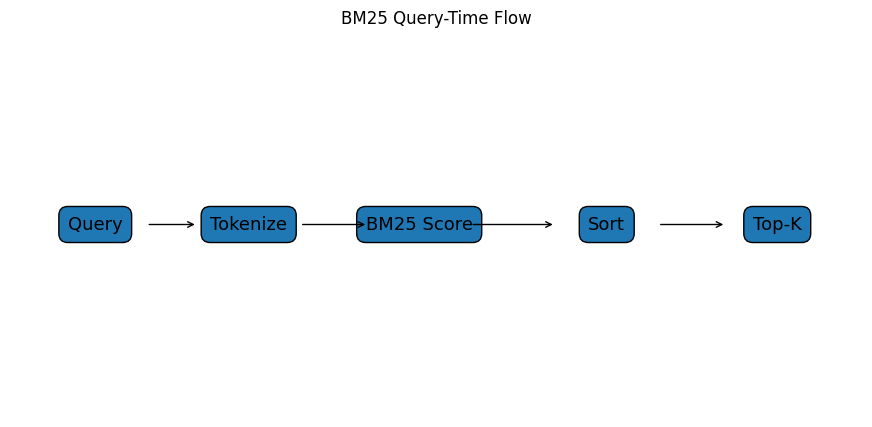

In [2]:
fig, ax = plt.subplots(figsize=(11,5))
ax.axis("off")
steps=[(0.1,"Query"),(0.28,"Tokenize"),(0.48,"BM25 Score"),(0.7,"Sort"),(0.9,"Top-K")]
for x,label in steps:
    ax.text(x,0.5,label,ha="center",va="center",fontsize=13,bbox=dict(boxstyle="round,pad=0.5"))
for i in range(len(steps)-1):
    ax.annotate("",xy=(steps[i+1][0]-0.06,0.5),xytext=(steps[i][0]+0.06,0.5),arrowprops=dict(arrowstyle="->"))
plt.title("BM25 Query-Time Flow")
plt.show()

# 3. Corpus With Metadata

Practical retrieval should preserve IDs and metadata, not only text.

In [3]:
documents = [
    {"id":"D1","title":"Cat Nutrition","category":"animals","text":"cat drinks milk"},
    {"id":"D2","title":"Cat Food","category":"animals","text":"cat cat eats fish"},
    {"id":"D3","title":"Dog Food","category":"animals","text":"dog eats food"},
    {"id":"D4","title":"Apple Salad","category":"food","text":"apple banana fruit salad"},
    {"id":"D5","title":"Apple Snack","category":"food","text":"apple apple fruit"},
    {"id":"D6","title":"Reading Habit","category":"books","text":"reading books improves vocabulary"},
    {"id":"D7","title":"Travel Note","category":"travel","text":"train travel is comfortable for short trips"},
]

df = pd.DataFrame(documents)
display(df)

,id,title,category,text
0,D1,Cat Nutrition,animals,cat drinks milk
1,D2,Cat Food,animals,cat cat eats fish
2,D3,Dog Food,animals,dog eats food
3,D4,Apple Salad,food,apple banana fruit salad
4,D5,Apple Snack,food,apple apple fruit
5,D6,Reading Habit,books,reading books improves vocabulary
6,D7,Travel Note,travel,train travel is comfortable for short trips


# 4. Reusable Tokenizer

Use the **same tokenizer** at index time and query time.

In [4]:
def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

sample="Cat, CAT, cat!"
print("Original:", sample)
print("Tokens:", tokenize(sample))

Original: Cat, CAT, cat!
Tokens: ['cat', 'cat', 'cat']


# 5. Prepare Corpus Statistics

At index time we want:

```text
tokens
term counts
document lengths
DF
avgdl
```

In [5]:
def prepare_corpus(documents):
    tokenized_docs={}
    term_counts={}
    doc_lengths={}

    for doc in documents:
        doc_id=doc["id"]
        tokens=tokenize(doc["text"])
        tokenized_docs[doc_id]=tokens
        term_counts[doc_id]=Counter(tokens)
        doc_lengths[doc_id]=len(tokens)

        print(f"\n{doc_id}")
        print("Text:", doc["text"])
        print("Tokens:", tokens)
        print("Counts:", term_counts[doc_id])
        print("Length:", len(tokens))

    return tokenized_docs, term_counts, doc_lengths

tokenized_docs, term_counts, doc_lengths = prepare_corpus(documents)


D1
Text: cat drinks milk
Tokens: ['cat', 'drinks', 'milk']
Counts: Counter({'cat': 1, 'drinks': 1, 'milk': 1})
Length: 3

D2
Text: cat cat eats fish
Tokens: ['cat', 'cat', 'eats', 'fish']
Counts: Counter({'cat': 2, 'eats': 1, 'fish': 1})
Length: 4

D3
Text: dog eats food
Tokens: ['dog', 'eats', 'food']
Counts: Counter({'dog': 1, 'eats': 1, 'food': 1})
Length: 3

D4
Text: apple banana fruit salad
Tokens: ['apple', 'banana', 'fruit', 'salad']
Counts: Counter({'apple': 1, 'banana': 1, 'fruit': 1, 'salad': 1})
Length: 4

D5
Text: apple apple fruit
Tokens: ['apple', 'apple', 'fruit']
Counts: Counter({'apple': 2, 'fruit': 1})
Length: 3

D6
Text: reading books improves vocabulary
Tokens: ['reading', 'books', 'improves', 'vocabulary']
Counts: Counter({'reading': 1, 'books': 1, 'improves': 1, 'vocabulary': 1})
Length: 4

D7
Text: train travel is comfortable for short trips
Tokens: ['train', 'travel', 'is', 'comfortable', 'for', 'short', 'trips']
Counts: Counter({'train': 1, 'travel': 1, 'is': 

In [6]:
N=len(documents)
vocabulary=sorted({t for tokens in tokenized_docs.values() for t in tokens})
df_map={term:sum(1 for tokens in tokenized_docs.values() if term in set(tokens)) for term in vocabulary}
avgdl=sum(doc_lengths.values())/N

print("N =", N)
print("Vocabulary size =", len(vocabulary))
print("avgdl =", avgdl)

stats=pd.DataFrame({"term":vocabulary,"df":[df_map[t] for t in vocabulary]}).sort_values("df",ascending=False)
display(stats)

N = 7
Vocabulary size = 22
avgdl = 4.0


,term,df
0,apple,2
3,cat,2
7,eats,2
11,fruit,2
4,comfortable,1
5,dog,1
20,trips,1
19,travel,1
18,train,1
17,short,1


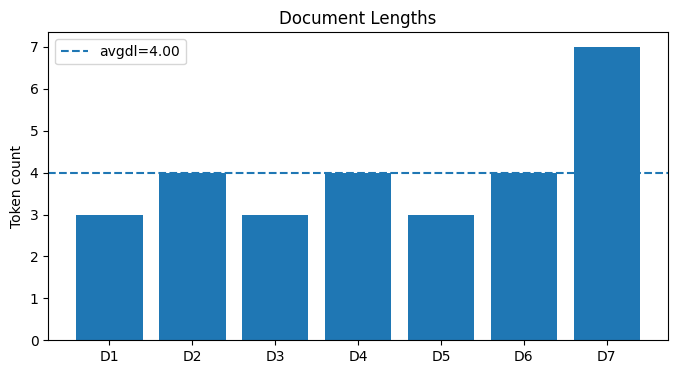

In [7]:
plt.figure(figsize=(8,4))
plt.bar(list(doc_lengths.keys()), list(doc_lengths.values()))
plt.axhline(avgdl, linestyle="--", label=f"avgdl={avgdl:.2f}")
plt.ylabel("Token count")
plt.title("Document Lengths")
plt.legend()
plt.show()

# CHECKPOINT 1

### Questions
1. What should happen at index time?
2. Why must document/query tokenization match?
3. What is `avgdl`?
4. Why precompute DF?

## Answers
1. Tokenization, TF/DF, document lengths and average length should be prepared before queries.
2. BM25 relies on exact lexical tokens, so inconsistent preprocessing breaks matching.
3. `avgdl` is the average token length across indexed documents.
4. IDF needs DF, so precomputing it makes query-time scoring cheaper.

# 6. Reusable BM25 Retriever Class

We now separate `fit()` from `search()`.

In [8]:
class BM25Retriever:
    def __init__(self, k1=1.5, b=0.75):
        self.k1=k1
        self.b=b
        self.is_fitted=False

    def fit(self, documents):
        self.documents=[dict(d) for d in documents]
        self.doc_map={d["id"]:d for d in self.documents}
        self.tokenized_docs={d["id"]:tokenize(d["text"]) for d in self.documents}
        self.term_counts={doc_id:Counter(tokens) for doc_id,tokens in self.tokenized_docs.items()}
        self.doc_lengths={doc_id:len(tokens) for doc_id,tokens in self.tokenized_docs.items()}
        self.N=len(self.documents)

        vocab=set()
        for tokens in self.tokenized_docs.values():
            vocab.update(tokens)
        self.vocabulary=sorted(vocab)
        self.df={term:sum(1 for tokens in self.tokenized_docs.values() if term in set(tokens)) for term in self.vocabulary}
        self.avgdl=(sum(self.doc_lengths.values())/self.N) if self.N else 0.0
        self.is_fitted=True

        print("BM25 index fitted")
        print("Documents:", self.N)
        print("Vocabulary:", len(self.vocabulary))
        print("avgdl:", self.avgdl)
        print("k1:", self.k1, "b:", self.b)
        return self

    def idf(self, term):
        if not self.is_fitted:
            raise RuntimeError("Call fit() first")
        df=self.df.get(term,0)
        return math.log(1 + (self.N-df+0.5)/(df+0.5))

    def score_document(self, query, doc_id):
        if not self.is_fitted:
            raise RuntimeError("Call fit() first")

        counts=self.term_counts[doc_id]
        doc_length=self.doc_lengths[doc_id]
        score=0.0

        for term in tokenize(query):
            tf=counts[term]
            if tf==0:
                continue

            idf=self.idf(term)
            length_factor = 1-self.b + self.b*(doc_length/self.avgdl)
            numerator = tf*(self.k1+1)
            denominator = tf + self.k1*length_factor
            score += idf*(numerator/denominator)

        return score

    def search(self, query, top_k=5):
        rows=[]
        for doc_id,doc in self.doc_map.items():
            rows.append({
                "id":doc_id,
                "title":doc.get("title"),
                "category":doc.get("category"),
                "text":doc.get("text"),
                "score":self.score_document(query,doc_id),
            })
        return (pd.DataFrame(rows)
                .sort_values("score",ascending=False)
                .head(top_k)
                .reset_index(drop=True))

In [9]:
retriever=BM25Retriever(k1=1.5,b=0.75)
retriever.fit(documents)

BM25 index fitted
Documents: 7
Vocabulary: 22
avgdl: 4.0
k1: 1.5 b: 0.75


# 7. Query-Time Search

In [10]:
result=retriever.search("cat milk", top_k=5)
display(result)

,id,title,category,text,score
0,D1,Cat Nutrition,animals,cat drinks milk,3.196763
1,D2,Cat Food,animals,cat cat eats fish,1.661644
2,D3,Dog Food,animals,dog eats food,0.000000
3,D4,Apple Salad,food,apple banana fruit salad,0.000000
4,D5,Apple Snack,food,apple apple fruit,0.000000


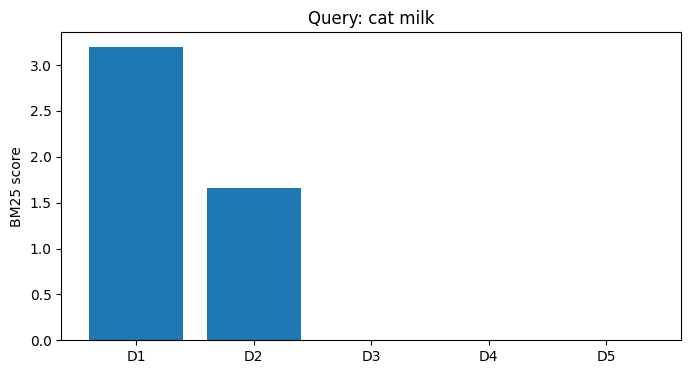

In [11]:
plt.figure(figsize=(8,4))
plt.bar(result["id"], result["score"])
plt.ylabel("BM25 score")
plt.title("Query: cat milk")
plt.show()

# 8. Explain One BM25 Score

A production debugger should show **why** a document got its score.

In [12]:
def explain_bm25_score(retriever, query, doc_id):
    counts=retriever.term_counts[doc_id]
    doc_length=retriever.doc_lengths[doc_id]
    rows=[]
    total=0.0

    print("QUERY:", query)
    print("DOCUMENT:", retriever.doc_map[doc_id]["text"])
    print("DOC LENGTH:", doc_length)
    print("AVGDL:", retriever.avgdl)

    for term in tokenize(query):
        tf=counts[term]
        df=retriever.df.get(term,0)
        idf=retriever.idf(term)

        if tf==0:
            length_factor=None
            tf_component=0.0
            term_score=0.0
        else:
            length_factor=1-retriever.b + retriever.b*(doc_length/retriever.avgdl)
            tf_component=(tf*(retriever.k1+1))/(tf + retriever.k1*length_factor)
            term_score=idf*tf_component

        total += term_score
        rows.append({
            "term":term, "tf":tf, "df":df, "idf":idf,
            "length_factor":length_factor, "tf_component":tf_component,
            "term_score":term_score
        })

        print(f"\nTERM={term}")
        print("TF=", tf, "DF=", df, "IDF=", idf)
        print("TF component=", tf_component)
        print("Term score=", term_score)

    print("\nTOTAL SCORE=", total)
    return pd.DataFrame(rows)

explanation=explain_bm25_score(retriever,"cat milk","D2")
display(explanation)

QUERY: cat milk
DOCUMENT: cat cat eats fish
DOC LENGTH: 4
AVGDL: 4.0

TERM=cat
TF= 2 DF= 2 IDF= 1.1631508098056809
TF component= 1.4285714285714286
Term score= 1.6616440140081155

TERM=milk
TF= 0 DF= 1 IDF= 1.6739764335716716
TF component= 0.0
Term score= 0.0

TOTAL SCORE= 1.6616440140081155


,term,tf,df,idf,length_factor,tf_component,term_score
0,cat,2,2,1.163151,1.0,1.428571,1.661644
1,milk,0,1,1.673976,NaN,0.000000,0.000000


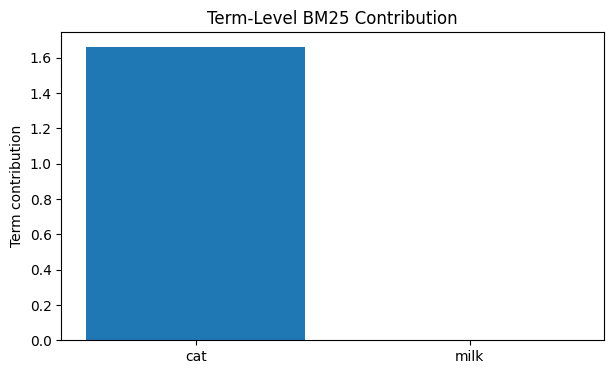

In [13]:
plt.figure(figsize=(7,4))
plt.bar(explanation["term"], explanation["term_score"])
plt.ylabel("Term contribution")
plt.title("Term-Level BM25 Contribution")
plt.show()

# CHECKPOINT 2

### Questions
1. Why separate `fit()` from `search()`?
2. Why keep document metadata?
3. Why is term-level score explanation useful?

## Answers
1. Index construction should happen much less often than user queries.
2. Downstream systems need IDs, titles, categories and other metadata.
3. It reveals whether TF, IDF, length normalization or tokenization caused a ranking result.

# 9. Batch Search

Useful for evaluation and regression testing.

In [ ]:
queries=["cat milk","apple fruit","reading vocabulary","train travel"]

for q in queries:
    print("\n"+"="*80)
    print("QUERY:", q)
    display(retriever.search(q,top_k=3))

In [ ]:
def batch_search(retriever, queries, top_k=3):
    rows=[]
    for query in queries:
        results=retriever.search(query,top_k=top_k)
        for rank,row in results.iterrows():
            rows.append({
                "query":query,
                "rank":rank+1,
                "doc_id":row["id"],
                "score":row["score"],
            })
    return pd.DataFrame(rows)

batch_result=batch_search(retriever,queries,3)
display(batch_result)

# 10. Add a New Document

Adding a document can change:

```text
N
DF
IDF
avgdl
```

Therefore BM25 scores are **corpus-dependent**.

In [ ]:
new_document={"id":"D8","title":"Milk for Cats","category":"animals","text":"cat milk food nutrition"}
updated_documents=documents+[new_document]

updated_retriever=BM25Retriever().fit(updated_documents)

display(updated_retriever.search("cat milk",top_k=5))

# 11. Compare Before vs After Reindexing

In [ ]:
before=retriever.search("cat milk",top_k=5)[["id","score"]].copy()
before["stage"]="before"

after=updated_retriever.search("cat milk",top_k=5)[["id","score"]].copy()
after["stage"]="after"

display(pd.concat([before,after],ignore_index=True))

# 12. Update an Existing Document

In [ ]:
def update_document(documents, doc_id, new_text):
    updated=[]
    for doc in documents:
        new_doc=dict(doc)
        if doc["id"]==doc_id:
            print("Updating", doc_id)
            print("Old:", doc["text"])
            print("New:", new_text)
            new_doc["text"]=new_text
        updated.append(new_doc)
    return updated

modified_documents=update_document(updated_documents,"D3","dog eats food and drinks water")
modified_retriever=BM25Retriever().fit(modified_documents)
display(modified_retriever.search("dog water",top_k=3))

# 13. Delete a Document

In [ ]:
def delete_document(documents, doc_id):
    return [doc for doc in documents if doc["id"]!=doc_id]

deleted_documents=delete_document(modified_documents,"D7")
print("New corpus size:", len(deleted_documents))

In [ ]:
fig, ax = plt.subplots(figsize=(11,5))
ax.axis("off")
steps=[(0.1,"Add / Update / Delete"),(0.34,"Source Docs"),(0.58,"Recompute Stats"),(0.8,"New BM25 Index")]
for x,label in steps:
    ax.text(x,0.5,label,ha="center",va="center",fontsize=12,bbox=dict(boxstyle="round,pad=0.45"))
for i in range(len(steps)-1):
    ax.annotate("",xy=(steps[i+1][0]-0.07,0.5),xytext=(steps[i][0]+0.07,0.5),arrowprops=dict(arrowstyle="->"))
plt.title("Simple Reindexing Strategy")
plt.show()

# CHECKPOINT 3

### Questions
1. Why can adding one document change BM25 scores?
2. What statistics may become stale?
3. What is the safest update strategy for a small corpus?

## Answers
1. BM25 depends on corpus-wide statistics.
2. `N`, DF, IDF, lengths and `avgdl`.
3. Update the source documents, then rebuild the index.

# 14. `rank_bm25` Library

After understanding the internals, you can use `BM25Okapi`.

In [ ]:
# Uncomment if needed:
# %pip install -q rank-bm25

In [ ]:
try:
    from rank_bm25 import BM25Okapi
    print("rank_bm25 imported")
except ImportError:
    BM25Okapi=None
    print("Install with: %pip install rank-bm25")

In [ ]:
if BM25Okapi is not None:
    corpus_tokens=[tokenize(doc["text"]) for doc in documents]
    library_bm25=BM25Okapi(corpus_tokens)
    query_tokens=tokenize("cat milk")
    scores=library_bm25.get_scores(query_tokens)

    lib_results=pd.DataFrame({
        "id":[d["id"] for d in documents],
        "text":[d["text"] for d in documents],
        "score":scores,
    }).sort_values("score",ascending=False)

    display(lib_results)

# 15. `get_top_n()` Convenience Method

In [ ]:
if BM25Okapi is not None:
    texts=[d["text"] for d in documents]
    top_docs=library_bm25.get_top_n(tokenize("apple fruit"),texts,n=3)
    for text in top_docs:
        print("-", text)

# 16. Custom vs Library Ranking

Different BM25 libraries can use slightly different IDF handling. Compare **ranking**, not only raw score magnitude.

In [ ]:
custom_rank=retriever.search("cat milk",top_k=len(documents))[["id","score"]].copy()
custom_rank["custom_rank"]=np.arange(len(custom_rank))+1
display(custom_rank)

# 17. BM25 Scores Are Not Probabilities

A score such as `4.2` does not mean 42% relevance. BM25 produces an uncalibrated ranking signal.

# 18. Top-K vs Fixed Threshold

A fixed threshold such as `score > 2` is risky because BM25 score distributions vary by query and corpus.

A common pattern is:

```text
BM25 Top-20
   ↓
Hybrid fusion
   ↓
Reranker
   ↓
Top-5
```

In [ ]:
for k in [1,3,5,7]:
    print("\nTOP-K =", k)
    display(retriever.search("cat milk",top_k=k))

# 19. Benchmark Index-Time and Query-Time

In [ ]:
start=time.perf_counter()
bench=BM25Retriever().fit(documents)
index_time=time.perf_counter()-start
print("Index time:", index_time, "seconds")

In [ ]:
benchmark_queries=["cat milk","apple fruit","dog food","reading vocabulary","train travel"]
latencies=[]
for q in benchmark_queries:
    start=time.perf_counter()
    bench.search(q,top_k=3)
    elapsed=time.perf_counter()-start
    latencies.append(elapsed)
    print(f"{q:<25} {elapsed:.8f} sec")
print("Average latency:", np.mean(latencies))

In [ ]:
plt.figure(figsize=(9,4))
plt.bar(benchmark_queries, latencies)
plt.xticks(rotation=30,ha="right")
plt.ylabel("Seconds")
plt.title("Tiny-Corpus Query Latency")
plt.tight_layout()
plt.show()

# 20. Why This From-Scratch Version Does Not Scale Forever

Our educational implementation scores every document.

A real engine uses an **inverted index**:

```text
query terms
   ↓
posting lists
   ↓
matching candidates only
   ↓
BM25 scoring
```

In [ ]:
fig, ax = plt.subplots(figsize=(11,6))
ax.axis("off")
ax.text(0.5,0.88,"QUERY: cat milk",ha="center",fontsize=15,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.25,0.58,"cat postings
D1, D2...",ha="center",fontsize=13,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.75,0.58,"milk postings
D1...",ha="center",fontsize=13,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.5,0.30,"Candidate Docs → BM25 → Top-K",ha="center",fontsize=14,bbox=dict(boxstyle="round,pad=0.5"))
ax.annotate("",xy=(0.25,0.66),xytext=(0.47,0.82),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.75,0.66),xytext=(0.53,0.82),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.45,0.37),xytext=(0.28,0.51),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.55,0.37),xytext=(0.72,0.51),arrowprops=dict(arrowstyle="->"))
plt.title("Production BM25 Scores Candidate Documents, Not Everything")
plt.show()

# CHECKPOINT 4

### Questions
1. Why is scoring every document inefficient at scale?
2. How does an inverted index help?
3. Why measure index time separately from query latency?
4. Why prefer Top-K over a universal score threshold?

## Answers
1. Query cost grows with corpus size.
2. Posting lists restrict scoring to documents containing query terms.
3. Indexing is occasional, while query latency affects every user request.
4. BM25 score ranges vary by query and corpus.

# 21. Edge Cases — Empty Query

In [ ]:
display(retriever.search("",top_k=3))

All scores are zero. In an API, reject or handle empty queries before retrieval.

# 22. Edge Case — Unknown Term

In [ ]:
display(retriever.search("zebra",top_k=5))

If the query term never occurs in the corpus, BM25 has no lexical evidence.

# 23. Mixed Known + Unknown Terms

In [ ]:
display(retriever.search("cat zebra",top_k=5))

`cat` contributes; `zebra` contributes nothing.

# 24. Metadata Filtering Preview

In [ ]:
food_documents=[d for d in documents if d["category"]=="food"]
food_retriever=BM25Retriever().fit(food_documents)
display(food_retriever.search("apple fruit",top_k=5))

# 25. API-Style Response Shape

In [ ]:
def search_response(retriever, query, top_k=3):
    results=retriever.search(query,top_k=top_k)
    return {
        "query":query,
        "top_k":top_k,
        "results":results.to_dict(orient="records")
    }

search_response(retriever,"cat milk",3)

# 26. Regression Tests

Retrieval logic should have simple tests so tokenizer/index changes do not silently break ranking.

In [ ]:
def run_basic_tests(retriever):
    cat_result=retriever.search("cat milk",top_k=2)
    assert set(cat_result["id"]).intersection({"D1","D2"})

    apple_result=retriever.search("apple fruit",top_k=2)
    assert set(apple_result["id"]).intersection({"D4","D5"})

    zebra_result=retriever.search("zebra",top_k=3)
    assert zebra_result["score"].max()==0

    print("All basic tests passed.")

run_basic_tests(retriever)

# 27. Debugging Checklist

If BM25 results look wrong, inspect:

```text
1. Is the document indexed?
2. Did tokenization produce the expected terms?
3. Is the query term in the vocabulary?
4. What is TF?
5. What is DF?
6. What is IDF?
7. What is document length?
8. What is avgdl?
9. What are k1 and b?
10. Was the corpus changed without rebuilding?
11. Is vocabulary mismatch occurring?
12. Is a metadata filter excluding the document?
```

In [ ]:
def debug_query(retriever, query, top_k=5):
    print("QUERY:", query)
    qterms=tokenize(query)
    print("TOKENS:", qterms)
    print("N:", retriever.N, "avgdl:", retriever.avgdl)

    for term in qterms:
        print(f"{term}: DF={retriever.df.get(term,0)}, IDF={retriever.idf(term):.4f}")

    result=retriever.search(query,top_k=top_k)
    display(result)
    return result

debug_query(retriever,"cat milk")

# 28. Production Architecture

In [ ]:
fig, ax = plt.subplots(figsize=(12,7))
ax.axis("off")
ax.text(0.25,0.88,"DOCUMENTS",ha="center",fontsize=14,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.25,0.66,"Parse + Tokenize",ha="center",fontsize=13,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.25,0.44,"BM25 INDEX",ha="center",fontsize=14,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.75,0.88,"USER QUERY",ha="center",fontsize=14,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.75,0.66,"Query Analyzer",ha="center",fontsize=13,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.75,0.44,"BM25 SEARCH",ha="center",fontsize=14,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.5,0.15,"Top-K → Hybrid Fusion → Reranker",ha="center",fontsize=14,bbox=dict(boxstyle="round,pad=0.55"))
ax.annotate("",xy=(0.25,0.72),xytext=(0.25,0.82),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.25,0.50),xytext=(0.25,0.60),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.75,0.72),xytext=(0.75,0.82),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.75,0.50),xytext=(0.75,0.60),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.58,0.22),xytext=(0.70,0.38),arrowprops=dict(arrowstyle="->"))
plt.title("Production BM25 Retrieval Architecture")
plt.show()

# CHECKPOINT 5

### Questions
1. What should be cached?
2. When does an index become stale?
3. Why are regression tests useful?
4. Where does BM25 sit in Hybrid Search?

## Answers
1. Tokenized documents, TF, DF, lengths, `avgdl`, vocabulary and index structures.
2. When corpus changes but statistics/index are not refreshed.
3. They catch unintended retrieval behavior changes.
4. BM25 is the lexical candidate-generation branch before fusion/reranking.

# 29. Interview Questions

### What happens at index time?
Tokenization, corpus statistics and index construction.

### What happens at query time?
Query tokenization, lexical candidate scoring, sorting and Top-K selection.

### Why not interpret BM25 score as probability?
Because it is an uncalibrated ranking score.

### Why can adding documents change old scores?
Because DF, IDF and `avgdl` are corpus-dependent.

### Why use an inverted index?
To avoid scoring every document.

### Why keep metadata?
Downstream fusion, reranking and context-building need stable document identities and attributes.

### What comes after BM25?
Dense retrieval results are combined with BM25 results, then fused and often reranked.

# 30. Interview Scenarios

### Scenario 1
You add 5,000 documents but do not refresh the index.

**Problem:** corpus statistics may be stale.

### Scenario 2
Query uses `car`, document uses `automobile`.

**Problem:** vocabulary mismatch.

### Scenario 3
BM25 score is `6.2`. Is that 62% relevance?

**No.**

### Scenario 4
Query latency is slow on millions of documents.

**Likely issue:** scoring every document instead of using posting lists/candidates.

### Scenario 5
What fields should be passed to a reranker?

```text
document ID
text
BM25 score
rank
metadata
```

# 31. One-Page Revision Map

```text
                INDEX TIME
                    │
             Source Documents
                    │
                Tokenize
                    │
          TF / DF / Lengths
                    │
               BM25 Index
                    │
                    ▼
                QUERY TIME
                    │
              Query Tokens
                    │
              BM25 Scoring
                    │
                  Top-K
                    │
              Hybrid Fusion
                    │
                Reranker
```

Practical concerns:

```text
metadata
updates
reindexing
caching
latency
tests
debugging
```

# 32. Practice Tasks

1. Add 10 documents and rebuild the retriever.
2. Compare rankings before and after adding one relevant document.
3. Update a document and inspect DF / `avgdl` changes.
4. Implement `delete_document()`.
5. Add category filtering.
6. Create 20 regression queries.
7. Measure average query latency over 100 queries.
8. Compare your custom ranking with `rank_bm25`.
9. Move `explain()` inside the retriever class.
10. Return JSON-ready results with IDs, text, score and metadata.

# 33. Final Takeaways

1. Practical BM25 requires more than the formula.
2. Separate index time from query time.
3. Tokenization must be consistent.
4. Cache corpus statistics.
5. BM25 scores are corpus-dependent.
6. Corpus changes may require reindexing.
7. `rank_bm25` is useful after understanding internals.
8. Large-scale systems should use inverted-index candidate retrieval.
9. Retrieval systems need tests and debugging tools.
10. BM25 becomes the lexical branch of Hybrid Search.

---

# Next Chapter — Chapter 7: Dense Vector Retrieval

Next we move to the semantic side:

```text
embeddings
dense vectors
query/document embeddings
semantic similarity
bi-encoders
embedding spaces
semantic strengths
exact-match weaknesses
```